In [3]:
import os
import pickle
import numpy as np
import matplotlib.pyplot as plt
import xarray as xr
import hmp
import hmp.io
import hmp.utils
from helper_functions import *
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [4]:
import pandas as pd
import seaborn as sns
import mne

# Load Data from participants

In [5]:
# We need HMP predictions and real EEG data to compare.
# Workflow: HMP predictions -> predict EEG -> compare with real EEG

# ----------------------------------------------------------------------
# 0. Choose which participant to load / predict
# ----------------------------------------------------------------------
EEG_DATA_PATH = os.path.join('data')
ESTIMATION_PATH = os.path.join(EEG_DATA_PATH, 'estimation_files')

SFREQ = 250                          # use 100 for speed/RAM
TSTEP = 1000 / SFREQ                 # ms per sample, for plotting
N_PARTICIPANTS = 2                   # how many participants to use


# ----------------------------------------------------------------------
# 1. Load real EEG (all participants, then keep the first 5)
# ----------------------------------------------------------------------
subj_names = sorted([x.split('.')[0] for x in os.listdir(EEG_DATA_PATH) if x.endswith('.fif')])
subj_files = [os.path.join(EEG_DATA_PATH, x + '.fif') for x in subj_names]

preprocessing = dict(sfreq=SFREQ, pick_channels='eeg')
epoch_data, info = hmp.io.read_mne_epochs(subj_files,
                                          montage='biosemi64',
                                          preprocessing_kwargs=preprocessing)

# Remove baseline that is not modelled by HMP
epoch_data = epoch_data.sel(sample=range(epoch_data.sample.max().values))

# Select only the first 2 participants
epoch_data = epoch_data.isel(recording=range(N_PARTICIPANTS))


# ----------------------------------------------------------------------
# 2. Load HMP predictions
# ----------------------------------------------------------------------
# estimates = model outputs (event probabilities); model = the fitted model object
with open(os.path.join(ESTIMATION_PATH, 'estimates.pkl'), 'rb') as f:
    estimates = pickle.load(f)
with open(os.path.join(ESTIMATION_PATH, 'model.pkl'), 'rb') as f:
    model = pickle.load(f)

# Event topographies per trial and event (one scalp map per trial; mean=False)
weights = hmp.utils.event_channels(epoch_data, estimates, mean=False).squeeze()
# Most likely time of each event, with the RT as the last column
times = hmp.utils.event_times(estimates, add_rt=True)


Processing dataset 0
Reading C:\Users\cleli\PycharmProjects\EEG_Predictions\data\0_epo.fif ...
    Found the data of interest:
        t =    -199.22 ...    3000.00 ms
        0 CTF compensation matrices available
Adding metadata with 6 columns
1116 matching events found
No baseline correction applied
0 projection items activated
Epoch data will be decimated by 2 to achieve a sampling frequency of 256.0Hz
Processing dataset 10
Reading C:\Users\cleli\PycharmProjects\EEG_Predictions\data\10_epo.fif ...
    Found the data of interest:
        t =    -199.22 ...    3000.00 ms
        0 CTF compensation matrices available
Adding metadata with 6 columns
1116 matching events found
No baseline correction applied
0 projection items activated
Epoch data will be decimated by 2 to achieve a sampling frequency of 256.0Hz
Processing dataset 11
Reading C:\Users\cleli\PycharmProjects\EEG_Predictions\data\11_epo.fif ...
    Found the data of interest:
        t =    -199.22 ...    3000.00 ms
        0 

In [6]:
print(weights)

<xarray.DataArray (channel: 32, trial: 2201, event: 4)> Size: 2MB
array([[[ 2.51445658e-06,  2.23177722e-06,  1.02894205e-06,
         -1.11500995e-05],
        [ 7.28296891e-06,  5.07227196e-06,  9.59510453e-06,
         -2.66117718e-06],
        [-1.82406950e-06, -7.91241109e-06,  8.42115639e-07,
         -1.28160718e-05],
        ...,
        [ 2.48841798e-06,  1.96344081e-06,  6.16345596e-06,
         -6.56507927e-06],
        [-1.37793700e-06,  1.51822087e-06,  2.49602590e-06,
          6.43086742e-06],
        [ 9.08850598e-06,  1.34931952e-05,  4.59114972e-06,
          4.15371687e-06]],

       [[ 2.30378532e-06,  2.71057138e-06,  5.73179204e-06,
         -5.69873873e-06],
        [ 5.46005822e-06,  2.93965604e-06,  1.06173602e-05,
         -4.31727813e-06],
        [-7.14721523e-07, -9.62150625e-06,  2.49261075e-06,
         -1.81507930e-05],
...
        [ 6.81514109e-07, -1.22516815e-06,  8.08329060e-06,
         -1.62710930e-05],
        [ 2.13946487e-06,  2.64669188e-06,  6

In [7]:
# ----------------------------------------------------------------------
# 3. Keep only the trials of the participants we selected
# ----------------------------------------------------------------------
recs = [str(r) for r in epoch_data.recording.values]
keep = np.where(np.isin(times.recording.values.astype(str), recs))[0]
# times: covers the whole model -> subset to the selected participants
keep_t = np.where(np.isin(times.recording.values.astype(str), recs))[0]
times = times.isel(trial=keep_t)


# Check that both refer to the same (recording, epoch) trials in the same order
t_ids = list(zip(times.recording.values.astype(str), times.epoch.values))
w_ids = list(zip(weights.recording.values.astype(str), weights.epoch.values))

# weights: already built from epoch_data, to have same order
weights = weights.isel(trial=[w_ids.index(t) for t in t_ids])

print("trials in times:", len(t_ids), "| trials in weights:", len(w_ids))
print("Same trials, same order:", t_ids == w_ids)

print("Participants:", recs, "| trials in model:", len(keep),
      "| epochs in data:", epoch_data.epoch.size * len(recs))
print("Channels in data:", epoch_data.channel.size, "| weights shape:", weights.shape)
print("NaNs in weights:", int(np.isnan(weights).sum()))


trials in times: 2201 | trials in weights: 2201
Same trials, same order: False
Participants: ['0', '10'] | trials in model: 2201 | epochs in data: 2234
Channels in data: 32 | weights shape: (32, 2201, 4)
NaNs in weights: 0


In [8]:
# ----------------------------------------------------------------------
# 4. Keep in epoch_data only the trials used by HMP (rejected trials -> NaN)
# ----------------------------------------------------------------------
# (recording, epoch) pairs kept by HMP
kept = set(zip(times.recording.values.astype(str), times.epoch.values.astype(int)))

# True where the (recording, epoch) pair was kept by HMP
mask = xr.DataArray(
    np.array([[(str(r), int(e)) in kept for e in epoch_data.epoch.values]
              for r in epoch_data.recording.values]),
    dims=("recording", "epoch"),
    coords={"recording": epoch_data.recording, "epoch": epoch_data.epoch},
)

# Rejected trials (and empty grid cells) become NaN
epoch_data = epoch_data.where(mask)

# Check: number of non-empty trials should equal the number of trials in times
n_real = int(epoch_data["data"].notnull().any(["channel", "sample"]).sum())
print("trials in epoch_data:", n_real, "| trials in times:", times.trial.size)

trials in epoch_data: 2201 | trials in times: 2201


In [9]:
# ----------------------------------------------------------------------
# 5. Cut every trial at its RT: HMP only models stimulus -> response
# ----------------------------------------------------------------------
last_dim = [d for d in times.dims if d != "trial"][0]
rt_vals = times.isel({last_dim: -1}).values                  # RT in samples
lookup = {(str(r), int(e)): v for r, e, v in
          zip(times.recording.values, times.epoch.values, rt_vals)}

rt_grid = xr.DataArray(
    [[lookup.get((str(r), int(e)), -1) for e in epoch_data.epoch.values]
     for r in epoch_data.recording.values],
    dims=("recording", "epoch"),
    coords={"recording": epoch_data.recording, "epoch": epoch_data.epoch},
)

epoch_data = epoch_data.where(epoch_data.sample < rt_grid)    # NaN from RT onwards

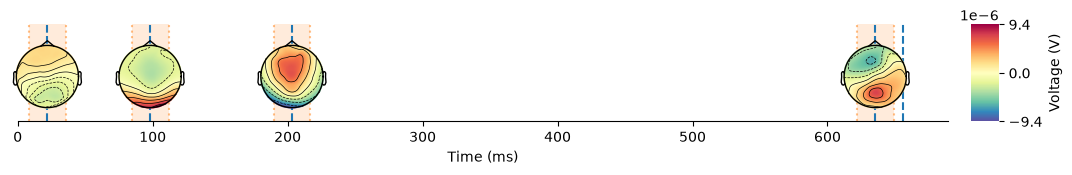

In [10]:
hmp.visu.plot_topo_timecourse(epoch_data, estimates, info, as_time=True, colorbar=True,)

# 1.1 Basic EEG Simulation 

In [11]:
# An example using the default assumption of HMP regarding the pattern in the data
pattern_assumption = {0:HalfSine(SFREQ, width=50), 1:HalfSine(SFREQ, width=50), 
                      2:HalfSine(SFREQ, width=50), 3:HalfSine(SFREQ, width=50)}
# one pattern by event (here 4 events)
default_sim = simulate_from_hmpfit(epoch_data, weights, times, pattern_assumption)
print(default_sim)

<xarray.Dataset> Size: 220MB
Dimensions:     (recording: 2, epoch: 1117, channel: 32, sample: 768)
Coordinates:
  * recording   (recording) <U2 16B '0' '10'
  * epoch       (epoch) int64 9kB 0 1 2 3 4 5 ... 1111 1112 1113 1114 1115 1116
    event_name  (recording, epoch) object 18kB 'stimulus/95' ... nan
    rt          (recording, epoch) float64 18kB 0.7197 0.4502 ... 0.623 nan
    condition   (recording, epoch) object 18kB 'accuracy' 'accuracy' ... nan
    side        (recording, epoch) object 18kB 'right' 'right' ... 'left' nan
    stimulus    (recording, epoch) object 18kB '95' '29' '42' ... '26' '42' nan
    response    (recording, epoch) object 18kB 'left' 'right' ... 'left' nan
    subject     (recording, epoch) <U2 18kB '0' '0' '0' '0' ... '10' '10' '10'
  * channel     (channel) <U3 384B 'Fp1' 'AF3' 'F7' 'F3' ... 'Fp2' 'Fz' 'Cz'
  * sample      (sample) int64 6kB 0 1 2 3 4 5 6 ... 761 762 763 764 765 766 767
Data variables:
    data        (recording, epoch, channel, sample) f

Text(0.5, 1.0, 'Default Half-Sine')

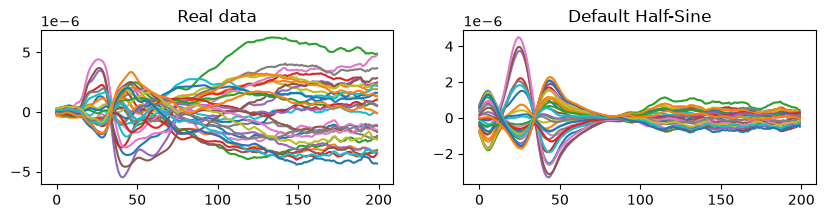

In [12]:
# Plotting the simulation
fig, ax = plt.subplots(1,2, figsize=(10, 2), sharey=False)
ax[0].plot(epoch_data.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[0].set_title('Real data')
ax[1].plot(default_sim.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial').data.T);
ax[1].set_title('Default Half-Sine')

# 1.2 Score Prediction

### R2 score: 

In [13]:
# ----------------------------------------------------------------------
# Case 1: nothing averaged -> one score per trial and per electrode
# "How well does HMP predict each single trial?"
# dims: (recording, epoch, channel)
# ----------------------------------------------------------------------
r2_trials = score(epoch_data, default_sim, "r2")

# ----------------------------------------------------------------------
# Case 2: trials averaged -> one score per participant and per electrode
# "How well does HMP predict each participant's average signal (ERP)?"
# dims: (recording, channel)
# ----------------------------------------------------------------------
r2_erp = score(epoch_data, default_sim, "r2", average_trial=True)

# ----------------------------------------------------------------------
# Case 2b: trials and participants averaged -> one score per electrode
# "How well does HMP predict the grand-average signal, on each electrode?"
# dims: (channel,)
# ----------------------------------------------------------------------
r2_grand = score(epoch_data, default_sim, "r2",
                 average_trial=True, average_participant=True)

# ----------------------------------------------------------------------
# Case 3: everything averaged -> one single number
# dims: none (a scalar)
# ----------------------------------------------------------------------
r2_global = score(epoch_data, default_sim, "r2",
                  average_trial=True, average_participant=True, average_channel=True)

print("Case 1  :", r2_trials.shape)
print("Case 2  :", r2_erp.shape)
print("Case 2b :", r2_grand.shape)
print("Case 3  :", float(r2_global))

Case 1  : (2, 1117, 32)
Case 2  : (2, 32)
Case 2b : (32,)
Case 3  : -0.12039827720870608


In [14]:
print(r2_grand)

<xarray.DataArray (channel: 32)> Size: 256B
array([-0.49050076, -0.22147706, -0.00367614,  0.21167652, -0.31190385,
        0.16656124,  0.30067517, -0.30819222, -0.2735884 ,  0.17312561,
        0.11076572,  0.09919237, -1.09536057, -0.03236253,  0.14505543,
       -0.08465094, -1.08282983,  0.03538707, -0.01328791,  0.06579188,
       -0.30593556,  0.00395227, -0.20968942, -0.03006091,  0.11474985,
       -0.75133791,  0.12825373,  0.27723728, -0.46006437,  0.26567017,
        0.0110599 , -0.28698071])
Coordinates:
  * channel  (channel) <U3 384B 'Fp1' 'AF3' 'F7' 'F3' ... 'AF4' 'Fp2' 'Fz' 'Cz'


### Correlation

In [15]:
# one trial: (samples, channels)
real = epoch_data.sel(sample=range(200)).stack(trial=['epoch', 'recording']).mean('trial')['data'].transpose('sample', 'channel').values
sim  = default_sim.sel(sample=range(200)).stack({'trial':['epoch','recording']}).mean('trial')['data'].transpose('sample', 'channel').values

print(pearson(real, sim))   # array of shape (n_channels,)

[0.8031701  0.797715   0.6837333  0.82265294 0.83792466 0.7360641
 0.4820469  0.7806865  0.8003498  0.643578   0.8334969  0.78129715
 0.8294389  0.74921244 0.78843266 0.7473521  0.6610796  0.64075166
 0.8020051  0.6073315  0.70787203 0.86216706 0.9087192  0.67877525
 0.53534764 0.8414747  0.75479496 0.33517885 0.7615499  0.69696957
 0.8251782  0.90999264]


For the Basic simulation where we just add Halfsines where the timings were detected, we achieve high correlation, but negative R². The shape is right but the amplitude or offset is wrong.

# 2.1 Tries to improve Simulation

### Least Squares implementation:

In [16]:
from Least_square import run_least_squares, only

out = run_least_squares(epoch_data, weights, times, pattern_assumption,
                        test_frac=0.2, seed=0, by="trial")
test = out["test_mask"]

# one score per electrode 
r2_test_per_electrode  = score(only(out["real_uv"], test),  only(out["pred_uv"], test),  "r2",average_trial=True, average_participant=True) 
r2_train_per_electrode = score(only(out["real_uv"], ~test), only(out["pred_uv"], ~test), "r2", average_trial=True, average_participant=True)

In [17]:
#one overall score: 
r2_test_overall  = score(only(out["real_uv"], test),  only(out["pred_uv"], test),  "r2",average_trial=True, average_participant=True,average_channel=True) 
r2_train_overall = score(only(out["real_uv"], ~test), only(out["pred_uv"], ~test), "r2", average_trial=True, average_participant=True,average_channel=True)
print(r2_train_overall)
print(r2_test_overall)

<xarray.DataArray ()> Size: 8B
array(-0.35723353)
<xarray.DataArray ()> Size: 8B
array(-0.23140122)


training set:
-0.3572335283347985


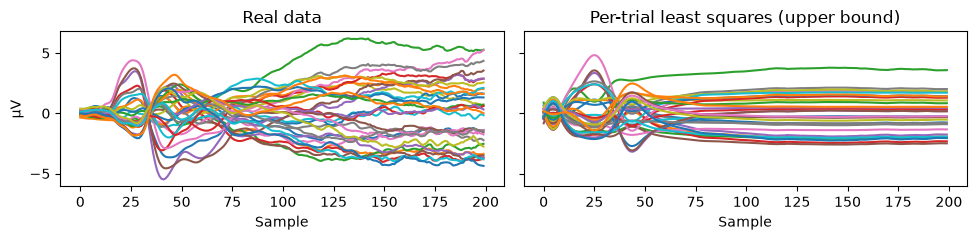

In [18]:
n = 200
fig, ax = plt.subplots(1, 2, figsize=(10, 2.5), sharey=True)
print("training set:")
for a, ds, title in zip(ax,[only(out["real_uv"], ~test), only(out["pred_uv"], ~test)],['Real data', 'Per-trial least squares (upper bound)']):
    erp = (ds['data'].sel(sample=range(n)).stack(trial=['epoch', 'recording']).mean('trial', skipna=True))# grand-average ERP: channel x sample
    a.plot(erp.transpose('sample', 'channel').values)
    a.set_title(title)
    a.set_xlabel('Sample')
ax[0].set_ylabel('µV')
plt.tight_layout()
print(float(r2_train_overall))

test set:
-0.23140122449077663


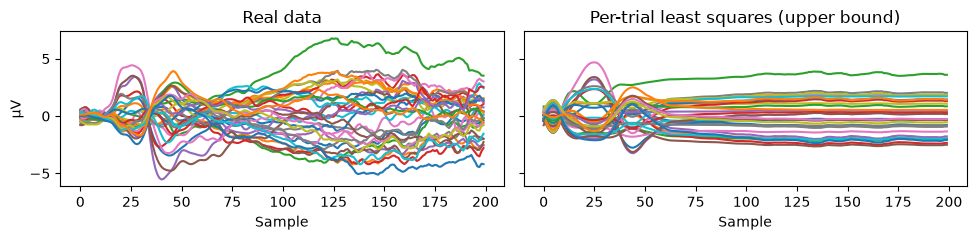

In [19]:
print("test set:")
n = 200
fig, ax = plt.subplots(1, 2, figsize=(10, 2.5), sharey=True)
for a, ds, title in zip(ax,[only(out["real_uv"], test), only(out["pred_uv"], test)],['Real data', 'Per-trial least squares (upper bound)']):
    erp = (ds['data'].sel(sample=range(n)).stack(trial=['epoch', 'recording']).mean('trial', skipna=True))# grand-average ERP: channel x sample
    a.plot(erp.transpose('sample', 'channel').values)
    a.set_title(title)
    a.set_xlabel('Sample')
ax[0].set_ylabel('µV')
plt.tight_layout()
print(float(r2_test_overall))


In [20]:
print(r2_test_per_electrode)
print(r2_train_per_electrode)

<xarray.DataArray (channel: 32)> Size: 256B
array([-0.98439043, -1.13393317, -0.08036766, -0.20290503,  0.04277542,
        0.01200664, -0.01022428, -0.01562448, -0.14054622, -0.67158886,
        0.01110357, -0.08830167,  0.01041283, -0.00564239, -0.21424889,
       -0.20214234, -0.01966048, -0.01306523, -0.64700542, -0.04300878,
       -0.4214361 , -0.16635963, -0.96493434, -0.04545443, -0.08403337,
       -0.67740105, -0.03321632, -0.00375643, -0.58503745, -0.0908095 ,
        0.06584005, -0.00188376])
Coordinates:
  * channel  (channel) <U3 384B 'Fp1' 'AF3' 'F7' 'F3' ... 'AF4' 'Fp2' 'Fz' 'Cz'
<xarray.DataArray (channel: 32)> Size: 256B
array([-0.86724082, -0.63926749, -0.91973733, -0.13890625,  0.20955626,
       -0.00713778, -0.02053466, -0.10401048, -1.15408211, -0.00310508,
        0.01514234, -0.81068761, -0.05673669, -0.43057911,  0.12092883,
       -0.09436476, -0.53477491, -0.49711681, -0.43255345, -0.0166633 ,
       -0.20397792, -0.61930273, -0.55591757, -0.37461554, -0.243

## Best possible output with Least squares (don't combine weights but fit least square for each individual trial and person) + add an intercept so that R2 is not negative

In [21]:
from Least_square import event_traces, fit_per_trial, noise_floor

traces = event_traces(epoch_data, weights, times, pattern_assumption)
real_uv = epoch_data.copy()
real_uv["data"] = epoch_data["data"] * 1e6

W_trial, ub_ds = fit_per_trial(real_uv, traces)

# score
r2_ub_trials = score(real_uv, ub_ds, "r2")                     # per trial and electrode
r2_ub_erp    = score(real_uv, ub_ds, "r2", average_trial=True,
                     average_participant=True, average_channel=True)

In [22]:
print("Median of R2 score per trial and electrode:",float(r2_ub_trials.median(skipna=True)))
print("Overall R2 score:", float(r2_ub_erp))

Median of R2 score per trial and electrode: 0.2507052762608436
Overall R2 score: 0.5858388553218634


Voltage at each electrode, averaged over all trials and participants:


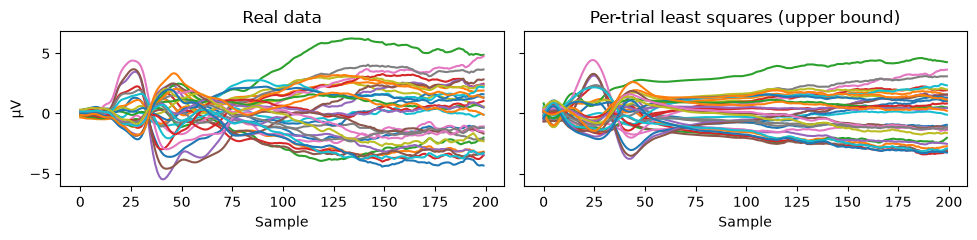

In [23]:
#each line is one electrode, averaged over all trials and participants
n = 200
fig, ax = plt.subplots(1, 2, figsize=(10, 2.5), sharey=True)
print("Voltage at each electrode, averaged over all trials and participants:")
for a, ds, title in zip(ax,[real_uv, ub_ds],['Real data', 'Per-trial least squares (upper bound)']):
    erp = (ds['data'].sel(sample=range(n)).stack(trial=['epoch', 'recording']).mean('trial', skipna=True))# grand-average ERP: channel x sample
    a.plot(erp.transpose('sample', 'channel').values)
    a.set_title(title)
    a.set_xlabel('Sample')
ax[0].set_ylabel('µV')
plt.tight_layout()

Voltage at each electrode in one single trial:


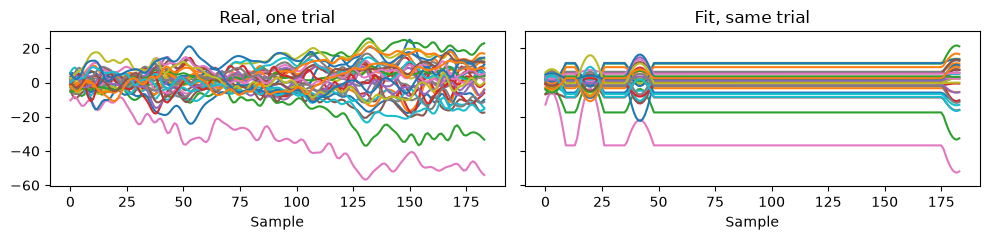

In [24]:
# each line is one electrode in a single trial, with no averaging
# first trial that has data
has_data = real_uv['data'].notnull().any(['channel', 'sample'])
rec_i, ep_i = [int(i[0]) for i in np.where(has_data.values)]
print("Voltage at each electrode in one single trial:")
fig, ax = plt.subplots(1, 2, figsize=(10, 2.5), sharey=True)
for a, ds, title in zip(ax, [real_uv, ub_ds], ['Real, one trial', 'Fit, same trial']):
    tr = ds['data'].isel(recording=rec_i, epoch=ep_i).transpose('sample', 'channel')
    a.plot(tr.values)
    a.set_title(title)
    a.set_xlabel('Sample')
plt.tight_layout()

## R2 if EEG is just noise

In [25]:
n_events = weights.sizes["event"]          # 4 in your case
floor = noise_floor(real_uv, n_events)     # DataArray (recording, epoch)-> for each subject, for each trial we get the noise floor

print(floor)
print("median noise floor:", float(floor.median(skipna=True)))

<xarray.DataArray 'data' (recording: 2, epoch: 1117)> Size: 18kB
array([[0.02185792, 0.03508772, 0.02409639, ..., 0.02684564, 0.02515723,
               nan],
       [0.02116402, 0.02631579, 0.03669725, ..., 0.01114206, 0.02515723,
               nan]], shape=(2, 1117))
Coordinates:
  * recording   (recording) <U2 16B '0' '10'
    subject     (recording) <U2 16B '0' '10'
  * epoch       (epoch) int64 9kB 0 1 2 3 4 5 ... 1111 1112 1113 1114 1115 1116
    event_name  (recording, epoch) object 18kB 'stimulus/95' ... nan
    rt          (recording, epoch) float64 18kB 0.7197 0.4502 ... 0.623 nan
    condition   (recording, epoch) object 18kB 'accuracy' 'accuracy' ... nan
    side        (recording, epoch) object 18kB 'right' 'right' ... 'left' nan
    stimulus    (recording, epoch) object 18kB '95' '29' '42' ... '26' '42' nan
    response    (recording, epoch) object 18kB 'left' 'right' ... 'left' nan
median noise floor: 0.028169014084507043


In [26]:
#Comparing noise floor R2 value with predictions/reconstruction:

ub_per_trial = r2_ub_trials.mean("channel", skipna=True)   # (recording, epoch) to get same dimension as noise floor, averages for all electrodes

ub_med = float(ub_per_trial.median(skipna=True))  #takes median R2
fl_med = float(floor.median(skipna=True))    #takes median noise R2
print(f"upper bound (median trial): {ub_med:.3f}")
print(f"noise floor (median trial): {fl_med:.3f}")
print(f"ratio: {ub_med / fl_med:.1f}x")

# trial by trial: is the bound above the floor?
above = (ub_per_trial > floor).where(ub_per_trial.notnull())   #computes the fraction of trials where the fitted upper bound beats the noise floor.
print("share of trials above the floor:", float(above.mean(skipna=True))) 

upper bound (median trial): 0.264
noise floor (median trial): 0.028
ratio: 9.4x
share of trials above the floor: 1.0


ratio of 1 means every scored trial had an upper-bound R² higher than its own noise floor.

# Visualizations

NameError: name 'participant_id' is not defined

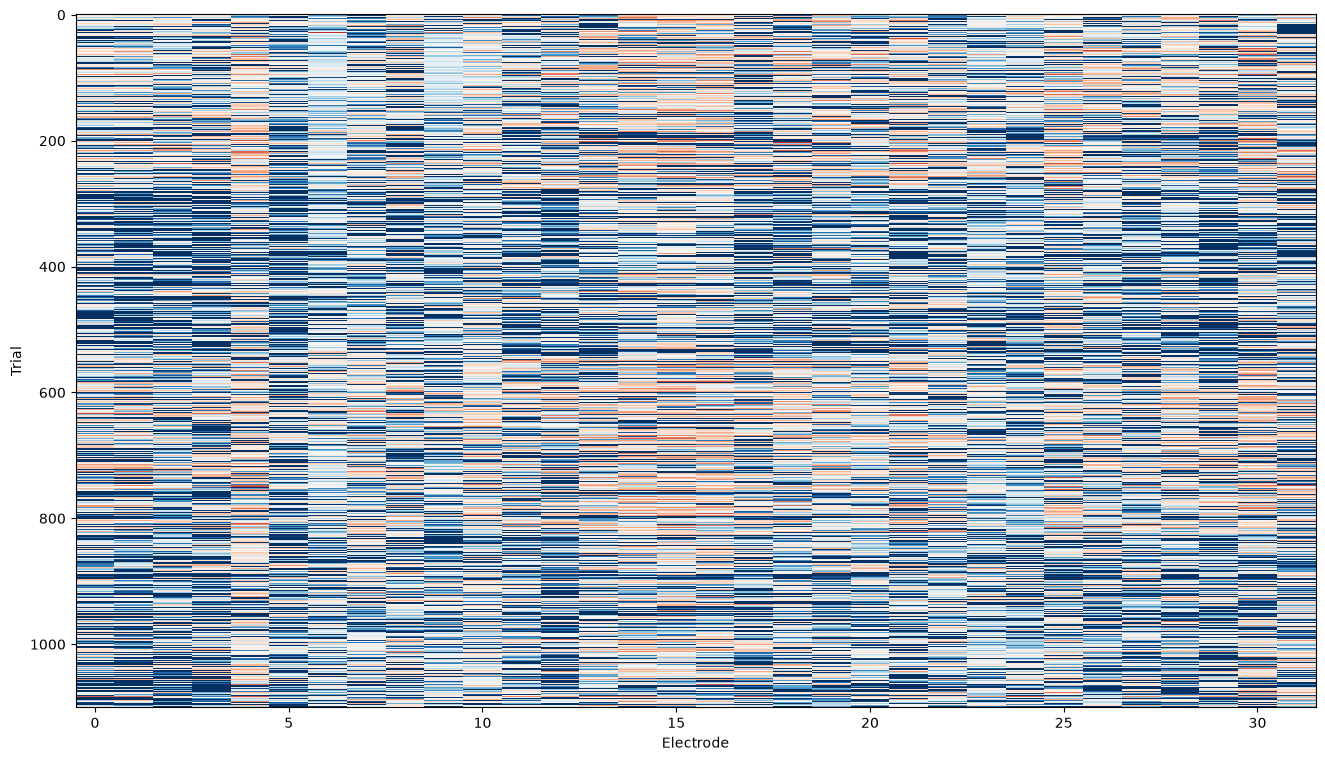

In [27]:
# Select one participant
participant = "10"

r2_heatmap = r2_trials.sel(recording=participant)

# Remove epochs with no valid scores
valid_epochs = r2_heatmap.notnull().any("channel")
r2_heatmap = r2_heatmap.sel(epoch=r2_heatmap.epoch[valid_epochs])

fig, ax = plt.subplots(figsize=(16, 9))

im = ax.imshow(
    r2_heatmap.values,
    aspect="auto",
    cmap="RdBu_r",
    interpolation="nearest",
    vmin=-1,
    vmax=1
)

ax.set_xlabel("Electrode")
ax.set_ylabel("Trial")
ax.set_title(f"R² per Trial and Electrode - Participant {participant_id}")

ax.set_xticks(range(len(r2_heatmap.channel)))
ax.set_xticklabels(r2_heatmap.channel.values, rotation=60, ha="right")

plt.colorbar(im, ax=ax, label="R²")
plt.tight_layout()
plt.show()


In [237]:
print(r2_trials.recording.values)

['0' '10']


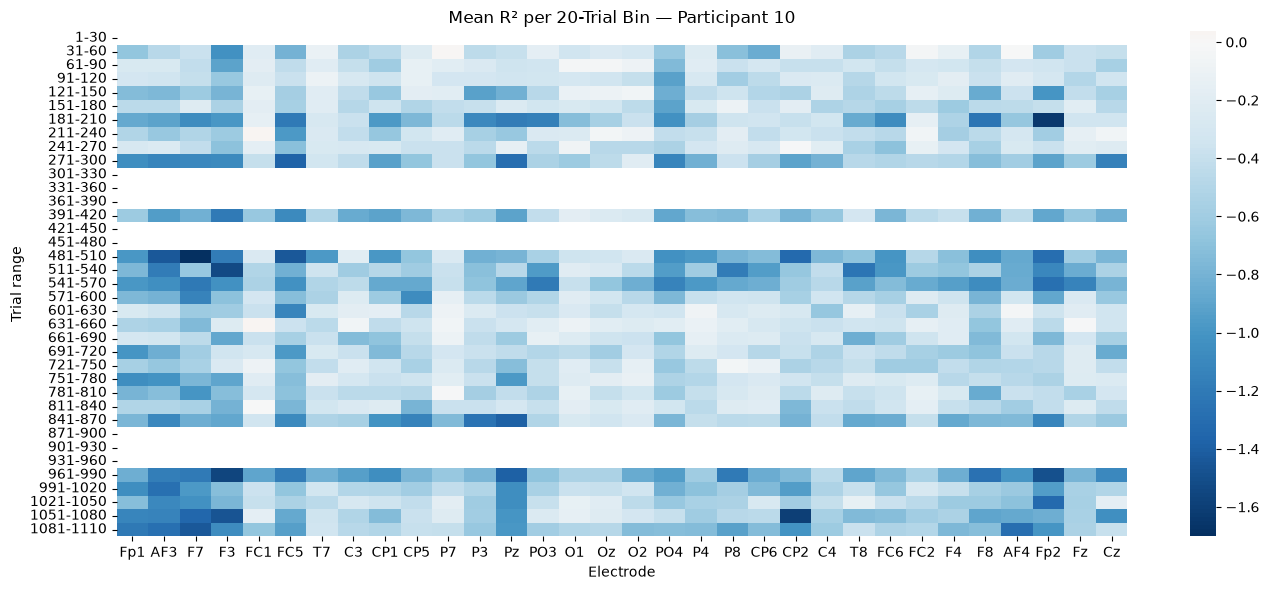

In [238]:
# Average every 30 consecutive trials
n_per_bin = 30

n_epochs = participant_data.sizes["epoch"]
n_bins = n_epochs // n_per_bin

# Keep complete bins
data = participant_data.isel(
    epoch=slice(0, n_bins * n_per_bin)
)

# Reshape into bins and average
binned_data = data.values.reshape(
    n_bins, n_per_bin, data.sizes["channel"]
).mean(axis=1)

plt.figure(figsize=(14, 6))

sns.heatmap(
    binned_data,
    cmap="RdBu_r",
    center=0,
    xticklabels=participant_data.channel.values,
    yticklabels=[f"{i*n_per_bin+1}-{(i+1)*n_per_bin}" for i in range(n_bins)]
)

plt.xlabel("Electrode")
plt.ylabel("Trial range")
plt.title(f"Mean R² per 20-Trial Bin — Participant {participant_id}")
plt.tight_layout()
plt.show()

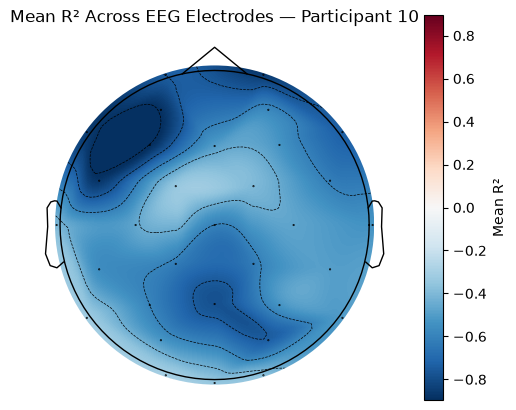

In [239]:
channels = list(mean_r2.channel.values)

picks = [info.ch_names.index(ch) for ch in channels]
info_eeg = mne.pick_info(info, picks)

fig, ax = plt.subplots(figsize=(6, 5))

im, _ = mne.viz.plot_topomap(
    mean_r2.values,
    info_eeg,
    ch_type="eeg",
    cmap="RdBu_r",
    contours=6,
    axes=ax,
    show=False
)

ax.set_title(f"Mean R² Across EEG Electrodes — Participant {participant_id}")

fig.colorbar(im, ax=ax, label="Mean R²")
plt.show()

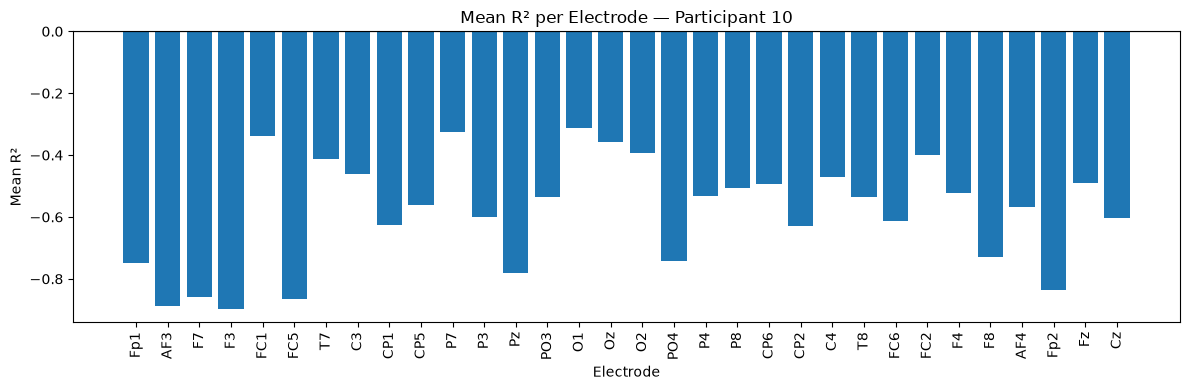

In [240]:
mean_r2 = participant_data.mean(dim="epoch", skipna=True)

plt.figure(figsize=(12, 4))

plt.bar(
    mean_r2.channel.values,
    mean_r2.values
)

plt.axhline(0, color="black", linewidth=0.8)
plt.ylabel("Mean R²")
plt.xlabel("Electrode")
plt.title(f"Mean R² per Electrode — Participant {participant_id}")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

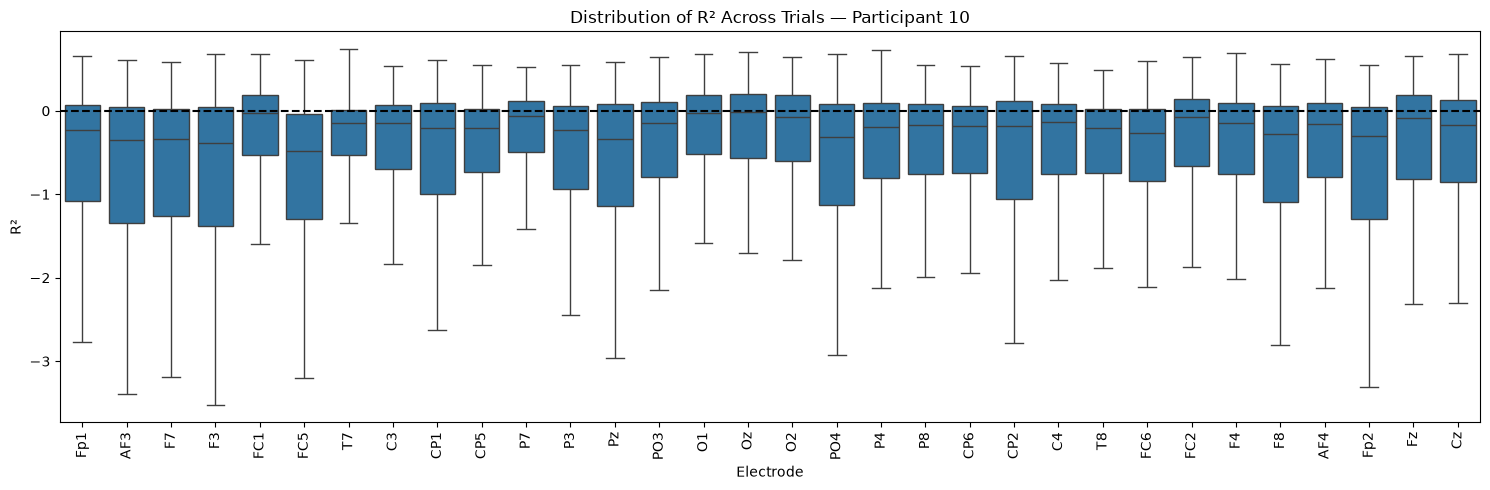

In [241]:
df = participant_data.to_dataframe(name="R2").reset_index()

plt.figure(figsize=(15, 5))

sns.boxplot(
    data=df,
    x="channel",
    y="R2",
    showfliers=False
)

plt.axhline(0, color="black", linestyle="--")
plt.xlabel("Electrode")
plt.ylabel("R²")
plt.title(f"Distribution of R² Across Trials — Participant {participant_id}")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

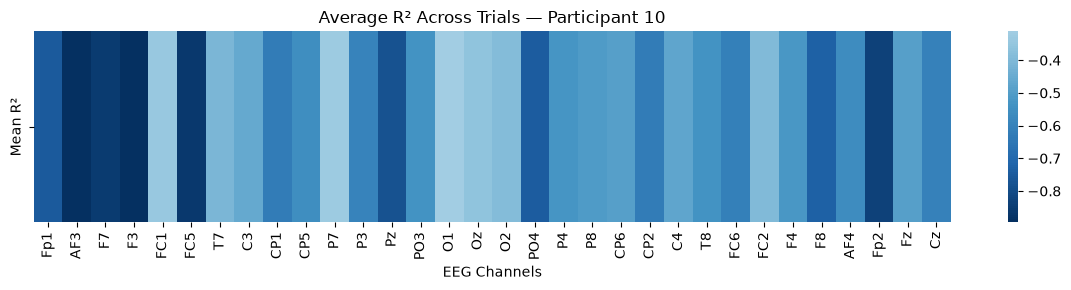

In [242]:
mean_r2 = participant_data.mean(dim="epoch", skipna=True)

plt.figure(figsize=(12, 3))

sns.heatmap(
    mean_r2.values.reshape(1, -1),
    cmap="RdBu_r",
    center=0,
    xticklabels=mean_r2.channel.values,
    yticklabels=["Mean R²"]
)

plt.xlabel("EEG Channels")
plt.title(f"Average R² Across Trials — Participant {participant_id}")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

In [243]:
for p in range(len(epoch_data.recording)):
    participant_id = epoch_data.recording.values[p]
    print(f"Index: {p}, Participant ID: {participant_id}")

Index: 0, Participant ID: 0
Index: 1, Participant ID: 10


## Does Least Squares Improve Reconstruction of exactly the same EEG trials?

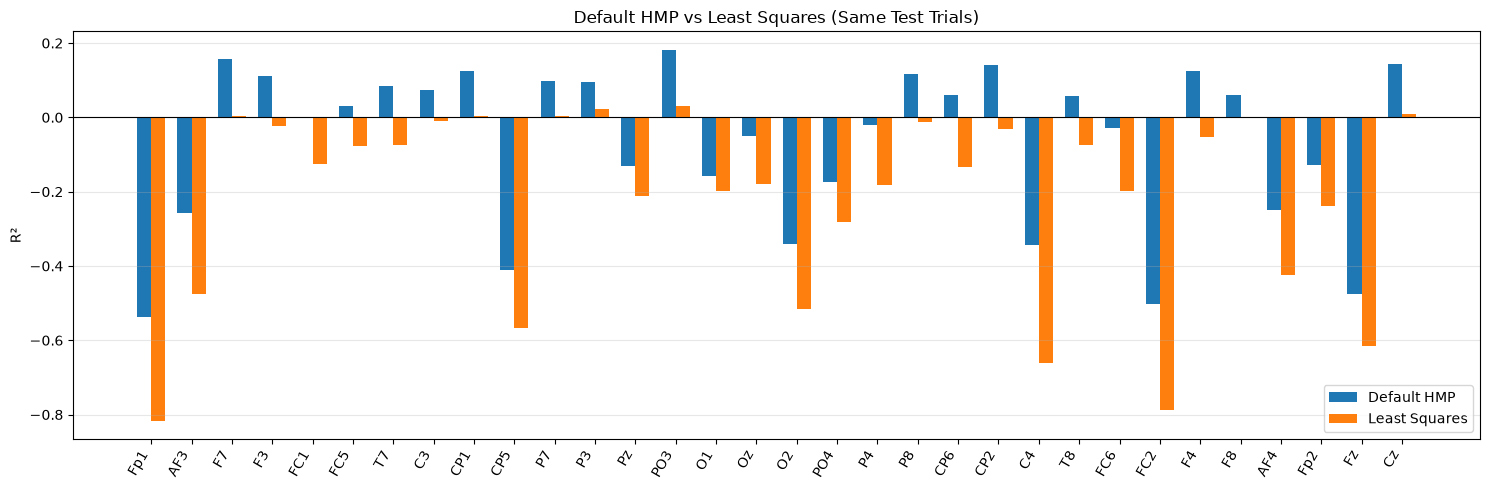

In [244]:

# Default HMP evaluated on the LS test trials

r2_default_test = score(
    only(epoch_data, test),
    only(default_sim, test),
    "r2",
    average_trial=True,
    average_participant=True
)

# Least Squares on the same test trials
r2_ls_test = r2_test_per_electrode

# Compare
fig, ax = plt.subplots(figsize=(15, 5))

x = np.arange(len(channels))
width = 0.35

ax.bar(x - width/2, r2_default_test.values, width,
       label="Default HMP")

ax.bar(x + width/2, r2_ls_test.values, width,
       label="Least Squares")

ax.axhline(0, color="black", linewidth=0.8)

ax.set_xticks(x)
ax.set_xticklabels(channels, rotation=60, ha="right")
ax.set_ylabel("R²")
ax.set_title("Default HMP vs Least Squares (Same Test Trials)")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()


# Improvement

In [245]:
improvement = r2_ls_test - r2_default_test

print("Electrodes improved:",
      int((improvement > 0).sum()), "/", len(channels))

print("Mean R² improvement:", float(improvement.mean()))

Electrodes improved: 0 / 32
Mean R² improvement: -0.1482180265318607


In [256]:
print(type(out))
print(out.keys())

<class 'dict'>
dict_keys(['W', 'pred_uv', 'real_uv', 'test_mask'])


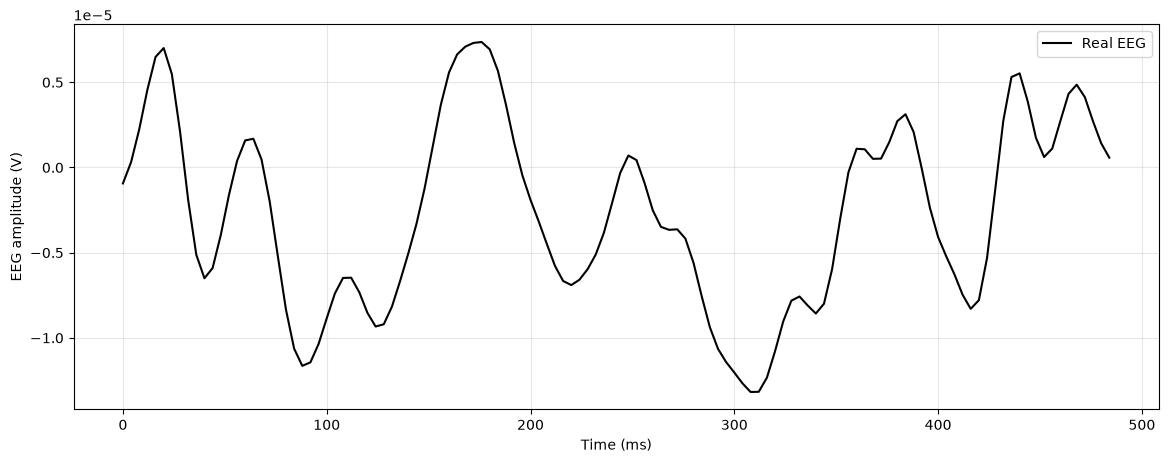

In [275]:
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(time_ms, real_signal, label="Real EEG", color="black")

ax.set_xlabel("Time (ms)")
ax.set_ylabel("EEG amplitude (V)")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

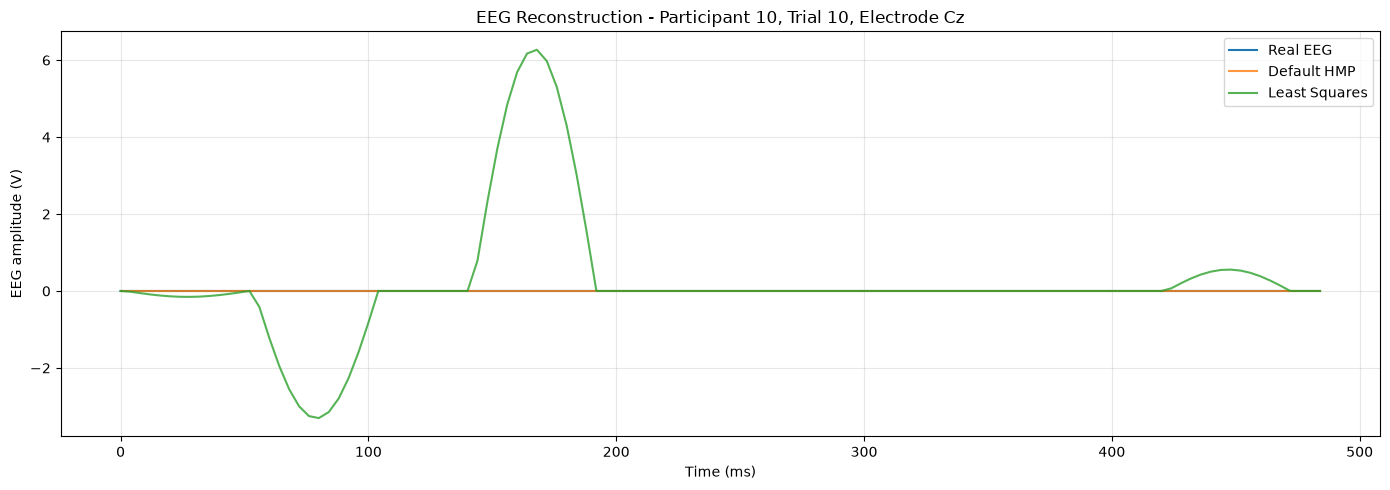

In [273]:

# Choose a participant, trial, and electrode
participant = "10"
trial = 10
electrode = "Cz"

real_signal = epoch_data.sel(
    recording=participant, epoch=trial, channel=electrode
)["data"].values

default_signal = default_sim.sel(
    recording=participant, epoch=trial, channel=electrode
)["data"].values

ls_signal = out["pred_uv"].sel(
    recording=participant, epoch=trial, channel=electrode
)["data"].values

# Plot
fig, ax = plt.subplots(figsize=(14, 5))

time_ms = np.arange(len(real_signal)) * 1000 / SFREQ

ax.plot(time_ms, real_signal, label="Real EEG", linewidth=1.5)
ax.plot(time_ms, default_signal, label="Default HMP", alpha=0.8)
ax.plot(time_ms, ls_signal, label="Least Squares", alpha=0.8)

ax.set_xlabel("Time (ms)")
ax.set_ylabel("EEG amplitude (V)")
ax.set_title(f"EEG Reconstruction - Participant {participant_id}, "
             f"Trial {trial}, Electrode {electrode}")

ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()


# Scalp Topography #

/var/folders/7l/k0d1r32n7vv4xq8plrz7qv3w0000gn/T/ipykernel_67173/2381198513.py:52: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


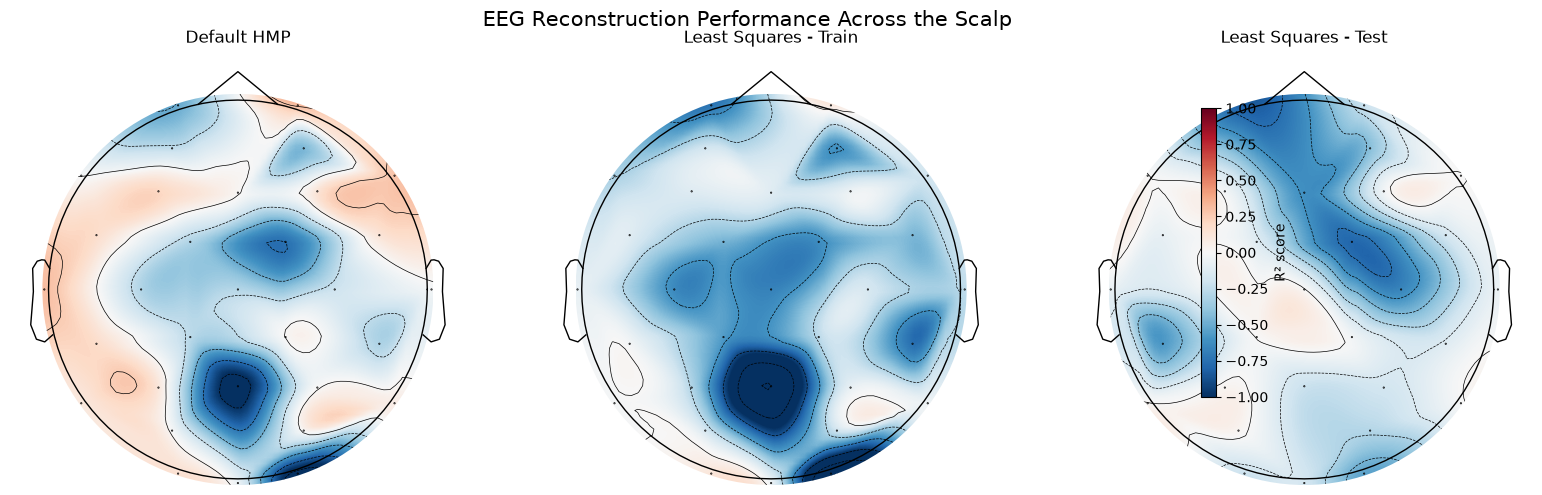

In [249]:

# --------------------------------------------------
# 1. Match the electrode order to the R² scores
# --------------------------------------------------

channels = list(r2_grand.channel.values)

# Keep only the EEG electrodes, in exactly the same order
picks = [info.ch_names.index(ch) for ch in channels]
info_eeg = mne.pick_info(info, picks)

# --------------------------------------------------
# 2. Prepare the three sets of scores
# --------------------------------------------------

scores = [
    (r2_grand.values, "Default HMP"),
    (r2_train_per_electrode.values, "Least Squares - Train"),
    (r2_test_per_electrode.values, "Least Squares - Test")
]

# --------------------------------------------------
# 3. Plot scalp topographies
# --------------------------------------------------

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for ax, (values, title) in zip(axes, scores):

    im, _ = mne.viz.plot_topomap(
        values,
        info_eeg,
        ch_type="eeg",
        axes=ax,
        cmap="RdBu_r",
        vlim=(-1, 1),
        contours=6,
        show=False
    )

    ax.set_title(title, fontsize=12)

# Shared colorbar
fig.colorbar(im, ax=axes, shrink=0.75, label="R² score")

fig.suptitle("EEG Reconstruction Performance Across the Scalp",
             fontsize=15)

plt.tight_layout()
plt.show()
